# Passive stretching: Maxwell and Kelvin–Voigt

Start with [Chapter 4](../docs/models/PassiveViscoelasticity.md).
The user-selected scope is **passive stretching first**, active contraction later.
Sources: [Roylance2001](https://web.mit.edu/course/3/3.11/www/modules/visco.pdf),
Maxwell equation (22) and Voigt creep; [Caporizzo2018](https://doi.org/10.1016/j.bpj.2018.09.019),
Figures 2D/3B for a candidate parallel network. See the [source audit](../docs/research/002-viscoelastic-source-audit.md)
for an unresolved difference with the paper's displayed equation (4).

**All values are synthetic**, not fitted cardiomyocyte parameters. The numerical
formulas are independently implemented Python, not code extracted from Lean.
The [Lean module](../CardioLean/Mechanics/LinearViscoelastic.lean) checks the exact
identities listed in the chapter; a graph is not physiological validation.

## 1. Hold and creep are different experiments

Tensile stress is in Pa, modulus in Pa, viscosity in Pa·s, and strain is dimensionless.
The basic elements use E=1000 Pa and η=500 Pa·s, giving τ=0.5 s.
Maxwell relaxation starts with a supplied post-loading stress. Kelvin–Voigt's
constant-strain hold stress omits the loading event: an ideal strain jump would
require an impulse, which is not modeled here. For creep we separately apply
constant stress 5 Pa from rest; Maxwell has an elastic jump at the loading time.

In [1]:
import math
from pathlib import Path
import matplotlib.pyplot as plt

E, eta = 1000.0, 500.0
strain_amplitude = 0.02
stress_initial = E * strain_amplitude
creep_stress = 5.0
tau = eta / E
assert E > 0 and eta > 0
times = [i * 0.001 for i in range(2001)]
maxwell_relaxation = [stress_initial * math.exp(-t / tau) for t in times]
kv_hold = [E * strain_amplitude for _ in times]
kv_creep = [creep_stress / E * (1 - math.exp(-t / tau)) for t in times]
maxwell_creep = [creep_stress / E + creep_stress * t / eta for t in times]
assert all(0 <= s <= stress_initial for s in maxwell_relaxation)
assert all(0 <= e <= creep_stress / E for e in kv_creep)
print(f"Basic-element time constant: {tau:g} s")
print(f"Maxwell stress at one time constant: {stress_initial * math.exp(-1):.6f} Pa")

Basic-element time constant: 0.5 s
Maxwell stress at one time constant: 7.357589 Pa


## 2. Finite ramp–hold–return for a candidate parallel network

The Kelvin–Voigt branch `(E₁,η₁)` is parallel to a Maxwell branch `(E₂,η₂)`.
Internal stress z obeys `z_dot=E₂*strain_rate−(E₂/η₂)*z`; total stress is
`E₁*strain+η₁*strain_rate+z`. A two-percent strain is ramped over 0.1 s, held
for 1 s, then returned over 0.1 s. z starts at zero and retains loading history.
The rate changes abruptly at the ramp corners; ordinary derivatives and the
power checks below apply only inside each smooth phase.

The internal-stress update is the exact exponential update for a constant strain
rate over each time step, not a general-purpose numerical solver.

These linear elements allow compressive as well as tensile stresses. The return
protocol can demand negative applied stress, and harmonic plots cross zero.
This is not active contraction. A tension-only or slackening cell requires an
additional constraint and appropriate prestrain/boundary conditions before
interpreting these curves as cell predictions.


In [2]:
E1, E2, eta1, eta2 = 1000.0, 2000.0, 100.0, 500.0
assert min(E1, E2, eta1, eta2) > 0


def strain_program(t):
    if t < 0.1:
        return 0.2 * t, 0.2
    if t < 1.1:
        return 0.02, 0.0
    if t < 1.2:
        return 0.02 - 0.2 * (t - 1.1), -0.2
    return 0.0, 0.0


dt = 0.001
ramp_times = [i * dt for i in range(2201)]
z = 0.0
network_stress, internal_stress, power_residuals, dissipations = [], [], [], []
for i, t in enumerate(ramp_times):
    strain, rate = strain_program(t)
    stress = E1 * strain + eta1 * rate + z
    z_rate = E2 * rate - E2 / eta2 * z
    dissipation = eta1 * rate ** 2 + z ** 2 / eta2
    storage_rate = E1 * strain * rate + z / E2 * z_rate
    network_stress.append(stress)
    internal_stress.append(z)
    dissipations.append(dissipation)
    if all(abs(t - corner) > dt / 10 for corner in (0.0, 0.1, 1.1, 1.2)):
        power_residuals.append(stress * rate - storage_rate - dissipation)
    if i + 1 < len(ramp_times):
        _, step_rate = strain_program(t + dt / 2)
        factor = math.exp(-dt * E2 / eta2)
        z = factor * z + eta2 * step_rate * (1 - factor)
assert min(dissipations) >= 0
assert max(map(abs, power_residuals)) < 1e-9
print(f"Checked {len(power_residuals)} smooth-phase power identities.")
print(f"Largest absolute power residual: {max(map(abs, power_residuals)):.3g} Pa/s")

Checked 2197 smooth-phase power identities.
Largest absolute power residual: 2.66e-15 Pa/s


## 3. Harmonic response and loop area

For strain `ε_a cos(ωt)`, use stress `ε_a(E′ cos(ωt)−E″ sin(ωt))`.
At a fixed ω the area of the oriented loop is the work per reference volume,
`∮σ dε = π E″ ε_a²`, in the steady harmonic regime. We numerically check
this formula. The complex-modulus and integrated-work statements are **not yet
Lean theorems**; the pointwise passive power identities are checked in Lean.

In [3]:
omega = 2 * math.pi
x = omega * eta2 / E2
storage_maxwell = E2 * x ** 2 / (1 + x ** 2)
loss_maxwell = E2 * x / (1 + x ** 2)
moduli = {
    "Kelvin–Voigt": (E1, omega * eta1),
    "Maxwell": (storage_maxwell, loss_maxwell),
    "Parallel KV + Maxwell": (E1 + storage_maxwell, omega * eta1 + loss_maxwell),
}
phase = [2 * math.pi * i / 2000 for i in range(2001)]
loop_strain = [strain_amplitude * math.cos(p) for p in phase]
loops = {}
for name, (storage, loss) in moduli.items():
    stress = [strain_amplitude * (storage * math.cos(p) - loss * math.sin(p)) for p in phase]
    loops[name] = stress
    work = sum((a + b) / 2 * (e2 - e1)
               for a, b, e1, e2 in zip(stress, stress[1:], loop_strain, loop_strain[1:]))
    expected = math.pi * loss * strain_amplitude ** 2
    assert work > 0
    assert math.isclose(work, expected, rel_tol=1e-4)
    print(f"{name}: cycle work {work:.6f} J/m^3; harmonic formula {expected:.6f}")

Kelvin–Voigt: cycle work 0.789567 J/m^3; harmonic formula 0.789568
Maxwell: cycle work 1.138557 J/m^3; harmonic formula 1.138559
Parallel KV + Maxwell: cycle work 1.928124 J/m^3; harmonic formula 1.928128


## 4. Keep the network derivation separate from a paper transcription

The source audit compares the standard laws for the pictured network with the
online HTML equation (4). For E₁=E₂=η₁=1 and η₂=2, a consistent pointwise tuple
has strain=0, strain_rate=1, acceleration=0, z=0, z_rate=1, stress=1, stress_rate=2.
The network coefficient gives 5=5; the displayed coefficient gives 4≠5.
The cause remains unresolved. This check does not invalidate the experiments,
reproduce the full article, or establish why the expressions differ.

In [4]:
e1, e2, n1, n2 = 1.0, 1.0, 1.0, 2.0
strain, rate, acceleration, z = 0.0, 1.0, 0.0, 0.0
z_rate = e2 * (rate - z / n2)
stress = e1 * strain + n1 * rate + z
stress_rate = e1 * rate + n1 * acceleration + z_rate
b_network = e1 * n2 + e2 * n2 + e2 * n1
b_displayed = e2 * n2 + e1 * n1 + e2 * n1
rhs = e2 * stress + n2 * stress_rate
lhs_network = n1 * n2 * acceleration + b_network * rate + e1 * e2 * strain
lhs_displayed = n1 * n2 * acceleration + b_displayed * rate + e1 * e2 * strain
assert lhs_network == rhs
assert lhs_displayed != rhs
print(f"Source audit: network LHS={lhs_network:g}; displayed LHS={lhs_displayed:g}; RHS={rhs:g}")

Source audit: network LHS=5; displayed LHS=4; RHS=5


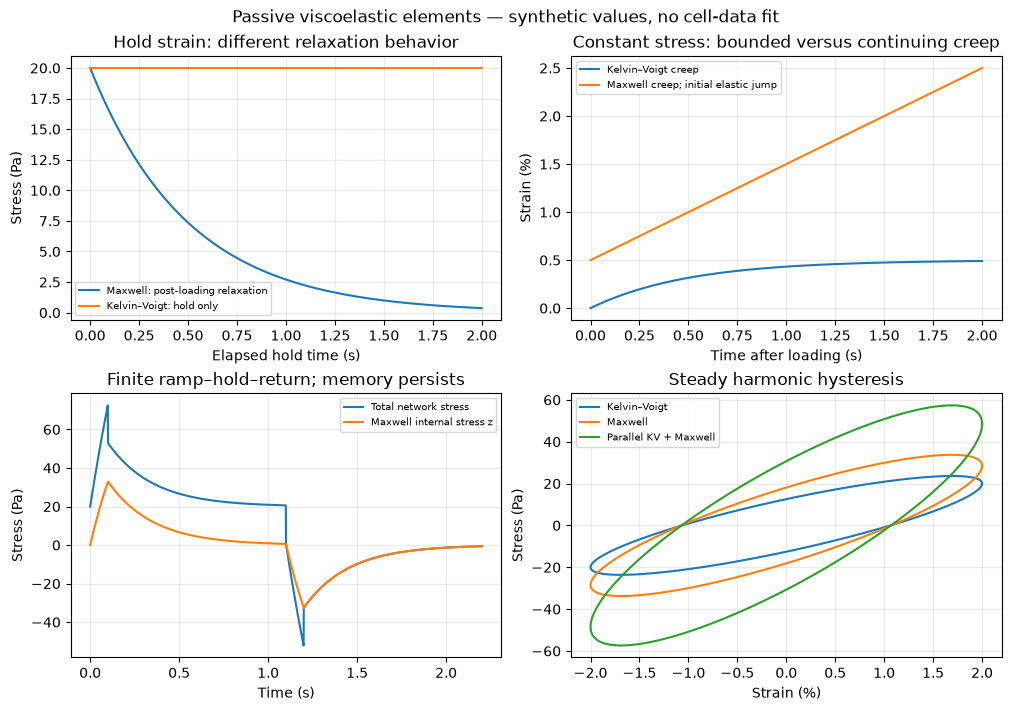

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7), layout="constrained")
axes[0, 0].plot(times, maxwell_relaxation, label="Maxwell: post-loading relaxation")
axes[0, 0].plot(times, kv_hold, label="Kelvin–Voigt: hold only")
axes[0, 0].set(xlabel="Elapsed hold time (s)", ylabel="Stress (Pa)", title="Hold strain: different relaxation behavior")
axes[0, 1].plot(times, [100 * e for e in kv_creep], label="Kelvin–Voigt creep")
axes[0, 1].plot(times, [100 * e for e in maxwell_creep], label="Maxwell creep; initial elastic jump")
axes[0, 1].set(xlabel="Time after loading (s)", ylabel="Strain (%)", title="Constant stress: bounded versus continuing creep")
axes[1, 0].plot(ramp_times, network_stress, label="Total network stress")
axes[1, 0].plot(ramp_times, internal_stress, label="Maxwell internal stress z")
axes[1, 0].set(xlabel="Time (s)", ylabel="Stress (Pa)", title="Finite ramp–hold–return; memory persists")
for name, stress in loops.items():
    axes[1, 1].plot([100 * e for e in loop_strain], stress, label=name)
axes[1, 1].set(xlabel="Strain (%)", ylabel="Stress (Pa)", title="Steady harmonic hysteresis")
for ax in axes.flat:
    ax.grid(alpha=0.25)
    ax.legend(fontsize=7)
fig.suptitle("Passive viscoelastic elements — synthetic values, no cell-data fit")
repo_root = Path.cwd() if Path("CardioLean.lean").exists() else Path.cwd().parent
assert (repo_root / "CardioLean.lean").is_file()
fig.savefig(repo_root / "docs/assets/passive-viscoelasticity.png", dpi=160,
            metadata={"Software": "CardioLean passive mechanics notebook"})
plt.show()

## Questions to investigate yourself

- Which experiment and boundary conditions would distinguish these candidate networks?
- Why is the Maxwell stress a state, rather than E times the current total strain?
- Which response quantities depend on specimen geometry and measurement direction?
- Why must loading corners and jumps be handled separately from smooth-phase derivatives?
- What data would justify parameters, a network topology, or a larger-strain extension?

Record your own predictions and corrections in [journal entry 005](../journal/005-passive-stretching.md).
Passive mechanics does not supply active contraction, calcium dynamics, or a complete heart model.